# SWOW и LWOW: наибольшие сильно связные компоненты

Для каждого датасета отдельно находим **наибольшую сильно связную компоненту** и строим её взвешенную матрицу смежности.

In [ ]:
import networkx as nx
import experiment as exp

In [2]:
swow = exp.load_associations("SWOW-EN18/strength.SWOW-EN.R1.20180827.csv")
lwow = exp.load_lwow("LWOW/FA_Llama3.csv")

print("Пар в SWOW:", len(swow))
print("Пар в LWOW:", len(lwow))

Пар в SWOW: 483589
Пар в LWOW: 293728


In [3]:
def largest_component_matrix(data):
    edges = data.groupby(["cue", "response"], as_index=False)["weight"].sum()
    graph = nx.from_pandas_edgelist(
        edges, "cue", "response", edge_attr="weight", create_using=nx.DiGraph()
    )
    component = max(nx.strongly_connected_components(graph), key=len)
    words = sorted(component)
    A = nx.to_scipy_sparse_array(graph, nodelist=words, weight="weight", format="csr")
    return words, A

In [4]:
swow_words, A_swow = largest_component_matrix(swow)
lwow_words, A_lwow = largest_component_matrix(lwow)

print("SWOW:", A_swow.shape, "вершин/размер матрицы,", A_swow.nnz, "рёбер")
print("LWOW:", A_lwow.shape, "вершин/размер матрицы,", A_lwow.nnz, "рёбер")

SWOW: (12178, 12178) вершин/размер матрицы, 387452 рёбер
LWOW: (10070, 10070) вершин/размер матрицы, 176520 рёбер


In [5]:
print("Первые слова SWOW:", swow_words[:10])
print("Первые слова LWOW:", lwow_words[:10])

print("Фрагмент SWOW:")
display(A_swow[:5, :5].toarray())
print("Фрагмент LWOW:")
display(A_lwow[:5, :5].toarray())

Первые слова SWOW: ['a', 'a few', 'a little', 'a lot', 'aardvark', 'abacus', 'abandon', 'abbey', 'abbreviation', 'abdicate']
Первые слова LWOW: ['a', 'a few', 'aardvark', 'ab', 'abandon', 'abbey', 'abbreviation', 'abdicate', 'abduct', 'abduction']
Фрагмент SWOW:


array([[0.01030928, 0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.04040404, 0.03030303, 0.        ],
       [0.        , 0.        , 0.        , 0.2020202 , 0.        ],
       [0.        , 0.        , 0.01      , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ]])

Фрагмент LWOW:


array([[0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.]])

Сделаем те же матрицы перехода P, что есть у Надежды уже.

$$P_{ij}=\frac{A_{ij}}{\sum_k A_{ik}}.$$

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import diags

def transition_matrix(A):
    row_sums = np.asarray(A.sum(axis=1)).ravel()
    return diags(1 / row_sums) @ A

P_swow = transition_matrix(A_swow)
P_lwow = transition_matrix(A_lwow)

print("Суммы строк P (SWOW):", np.asarray(P_swow.sum(axis=1)).ravel()[:5])
print("Суммы строк P (LWOW):", np.asarray(P_lwow.sum(axis=1)).ravel()[:5])

Суммы строк P (SWOW): [1. 1. 1. 1. 1.]
Суммы строк P (LWOW): [1. 1. 1. 1. 1.]


Вычисляем полные спектры

In [7]:
# Полный спектр A для SWOW
eig_A_swow = np.linalg.eigvals(A_swow.toarray())
print("SWOW, A:", len(eig_A_swow), "собственных значений")

SWOW, A: 12178 собственных значений


In [8]:
# Полный спектр P для SWOW
eig_P_swow = np.linalg.eigvals(P_swow.toarray())
print("SWOW, P:", len(eig_P_swow), "собственных значений")

SWOW, P: 12178 собственных значений


In [9]:
# Полный спектр A для LWOW
eig_A_lwow = np.linalg.eigvals(A_lwow.toarray())
print("LWOW, A:", len(eig_A_lwow), "собственных значений")

LWOW, A: 10070 собственных значений


In [10]:
# Полный спектр P для LWOW
eig_P_lwow = np.linalg.eigvals(P_lwow.toarray())
print("LWOW, P:", len(eig_P_lwow), "собственных значений")

LWOW, P: 10070 собственных значений


В первом столбце — спектры $A$, во втором — $P$. В верхней строке — SWOW, в нижней — LWOW. 

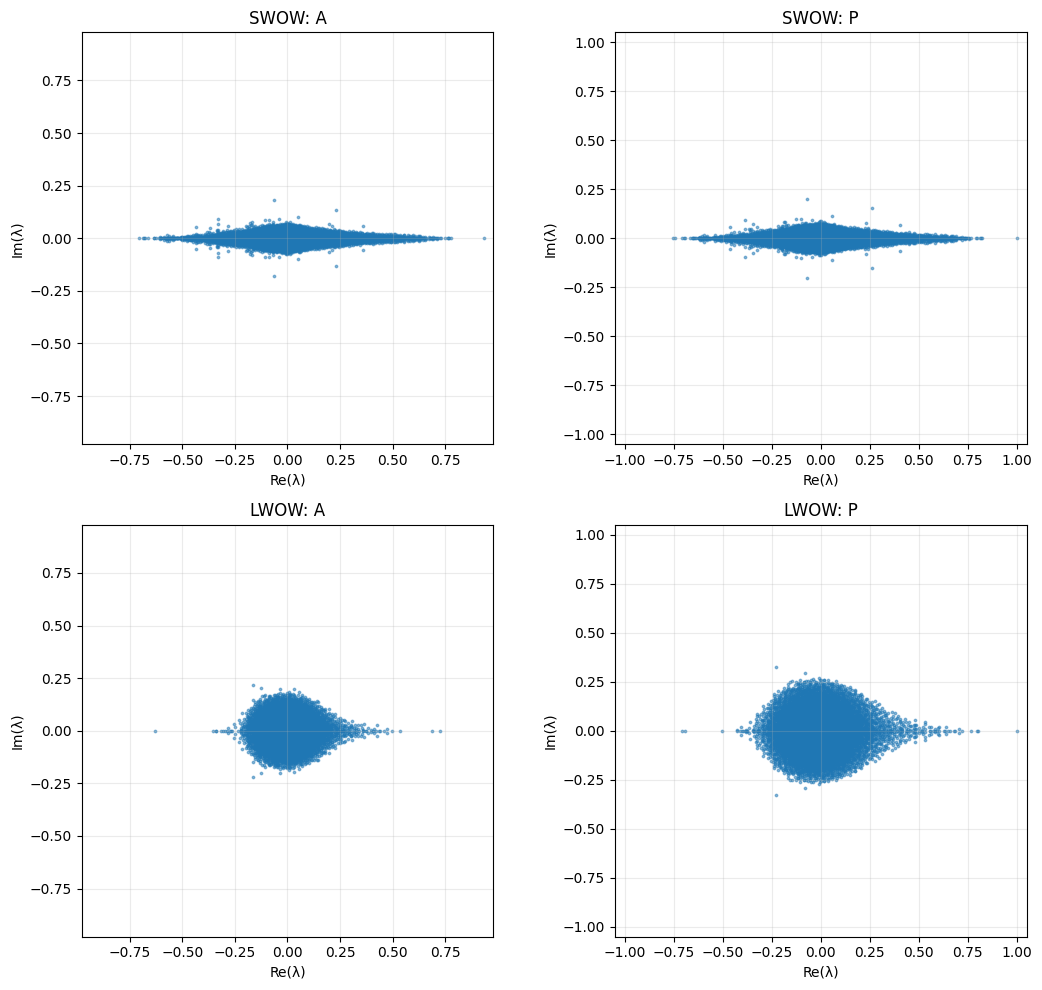

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(11, 10))

limit_A = 1.05 * max(np.max(np.abs(eig_A_swow)), np.max(np.abs(eig_A_lwow)))
limit_P = 1.05 * max(np.max(np.abs(eig_P_swow)), np.max(np.abs(eig_P_lwow)))

spectra = [
    (eig_A_swow, "SWOW: A", limit_A),
    (eig_P_swow, "SWOW: P", limit_P),
    (eig_A_lwow, "LWOW: A", limit_A),
    (eig_P_lwow, "LWOW: P", limit_P),
]

for ax, (values, title, limit) in zip(axes.flat, spectra):
    ax.scatter(values.real, values.imag, s=3, alpha=0.5)
    ax.set_title(title)
    ax.set_xlabel("Re(λ)")
    ax.set_ylabel("Im(λ)")
    ax.set_xlim(-limit, limit)
    ax.set_ylim(-limit, limit)
    ax.set_aspect("equal")
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()